# 03 · Well performance

Notebook 02 gave us trustworthy data. Now we ask the questions the project is really about:

1. **Injection side:** how hard do we have to push to inject 10 bpm, and is that changing? (*pressure and injectivity*)
2. **Recovery:** how much of the injected water comes back? (*volume recovery*)
3. **Steam:** part of the hot water flashes to steam at the separator. How much? (*we calculate it from physics*)
4. **Efficiency:** the report's headline number is **mass flow out ÷ mass flow in**, about 90%. Can we reproduce it independently?
5. **Uncertainty:** how much does the answer depend on the choices we made?

> **New tools in this notebook:** steam tables (the `iapws` library), `np.interp` for fast look-ups, `ax.twinx()` for two y-axes, and a horizontal bar chart for sensitivity. As before, each is explained when it first appears.

In [1]:
import sys
sys.path.insert(0, "../src")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from load import load_clean, load_flow_calibration, load_constants, load_manual_tp
from clean import temperature_offset
from analysis import (separator_conditions, steam_fraction, mass_flows,
                      injectivity_index, linear_trend)
from plots import apply_style, savefig, shade_window

apply_style()

d = load_clean("30s")                       # the cleaned data from notebook 02
steady = d[d["valid_steady"]].copy()        # only rows where injection is steady
print(f"{len(steady):,} steady rows from {steady.index.min()} to {steady.index.max()}")

65,856 steady rows from 2024-08-11 08:05:00 to 2024-09-04 06:00:10


## 1. Which period are we measuring?

In notebook 02 we flagged the *injection* as steady, but we noticed the *production* side was still developing. So before computing averages, let's find the period when the **efficiency itself stops changing**, using the same mass-flow calculation we build in section 5. (You'll see how `mass_flows` works shortly; for now we just need its efficiency.)

The rule: working backwards from the end, keep including days while the daily efficiency stays within 2% of the final value. The first day that breaks the rule marks where the plateau begins.

In [2]:
mf = mass_flows(steady)                                   # mass flows for every steady row
daily_eff = mf["efficiency"].groupby(steady.index.date).median()

final = daily_eff.iloc[-3:].median()                      # level at the end of the test
close = ((daily_eff - final).abs() / final) <= 0.02       # True where within 2% of that level

plateau_start = None
for day in reversed(daily_eff.index):                     # walk backwards from the last day
    if close[day]:
        plateau_start = day
    else:
        break

plateau = steady.loc[str(plateau_start):]
print("Final efficiency level :", round(final, 3))
print("Plateau starts         :", plateau_start)
print("Plateau length         :", plateau.index.normalize().nunique(), "days,", f"{len(plateau):,}", "rows")

Final efficiency level : 0.906
Plateau starts         : 2024-08-29
Plateau length         : 7 days, 18,001 rows


> **Learn:** `steady.loc["2024-08-29":]` selects every row from that date to the end. Slicing a table by date text is one of the most convenient pandas features for time series.

We will use this **plateau window** for our headline numbers, and show the whole steady period too, so you can see how the well *evolved*.

## 2. Injection pressure and injectivity

**Injectivity** says how easily the rock accepts water: more water for less pressure is better. We use a simple, honest version:

$$\text{injectivity} = \frac{\text{injection rate (gpm)}}{\text{wellhead pressure (psi)}} \times 100$$

so it is "gpm per 100 psi". 

> **Careful:** this uses *wellhead* pressure, which includes the weight of the water column and pipe friction, not just the pressure the rock sees. Because we inject at a constant rate with similar cold water, those extra terms stay roughly constant, so the **trend** is meaningful, but the absolute number is not a true reservoir property.

Pressure starts to decline after: 2024-08-21


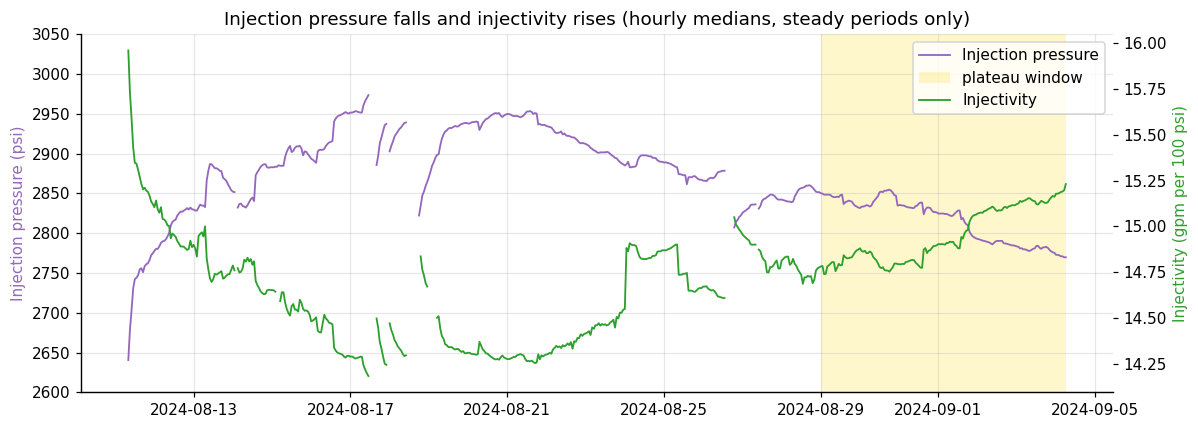

In [3]:
hs = steady.drop(columns=["phase", "valid_steady"]).resample("1h").median()   # hourly medians
hs["injectivity"] = injectivity_index(hs)

daily_p = steady["p_inj_psi"].resample("1D").median().dropna()      # one value per day, on a real date index
# Highest daily pressure AFTER the 17-18 Aug pump stops: where the pressure begins to fall
trend_start = daily_p.loc["2024-08-19":].idxmax().date()
print("Pressure starts to decline after:", trend_start)

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(hs.index, hs["p_inj_psi"], color="tab:purple", lw=1.2, label="Injection pressure")
ax.set_ylabel("Injection pressure (psi)", color="tab:purple"); ax.set_ylim(2600, 3050)
ax2 = ax.twinx()
ax2.plot(hs.index, hs["injectivity"], color="tab:green", lw=1.2, label="Injectivity")
ax2.set_ylabel("Injectivity (gpm per 100 psi)", color="tab:green"); ax2.grid(False)
shade_window(ax, plateau.index.min(), plateau.index.max(), label="plateau window")
ax.set_title("Injection pressure falls and injectivity rises (hourly medians, steady periods only)")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper right")          # one combined legend for both axes
savefig(fig, "03_pressure_injectivity.png"); plt.show()

> **Learn:** `ax.twinx()` creates a second y-axis on the right that shares the same time axis, perfect for two quantities with different units. I coloured each axis label to match its line.

Pressure rises during the first days (the fractures are being pressurised) and then falls. Injectivity moves the opposite way, as it should (same rate, lower pressure).

**One thing to explain:** injectivity jumps up on 24 Aug and drops back on 26 Aug. That is not the rock changing. The pump briefly ran slightly faster (about 10.2 bpm instead of 10), and injectivity is *rate ÷ pressure*, so it reacts to the rate change immediately, while the pressure takes longer to respond. This is why **pressure is the cleaner indicator** here, and why we fit the pressure trend first. Let's put numbers on the decline with a straight-line fit:

In [4]:
p_trend = linear_trend(hs.loc[str(trend_start):, "p_inj_psi"])
i_trend = linear_trend(hs.loc[str(trend_start):, "injectivity"])
p0 = hs.loc[str(trend_start), "p_inj_psi"].median()

print(f"From {trend_start} to the end ({p_trend['days']:.1f} days):")
print(f"  Injection pressure: {p_trend['slope_per_day']:+.1f} psi/day  (total {p_trend['change']:+.0f} psi, {p_trend['change']/p0*100:+.1f}%)   R² = {p_trend['r2']:.2f}")
print(f"  Injectivity       : {i_trend['slope_per_day']:+.3f} gpm/100psi per day  (total {i_trend['change']:+.2f}, from about {hs.loc[str(trend_start):, 'injectivity'].iloc[:24].mean():.1f})")

From 2024-08-21 to the end (14.2 days):
  Injection pressure: -11.1 psi/day  (total -158 psi, -5.4%)   R² = 0.91
  Injectivity       : +0.053 gpm/100psi per day  (total +0.75, from about 14.3)


This matches the report's wording: *"injection pressures were high but starting to decline slightly"*, with roughly **160 psi (about 5%)** of decline over two weeks.

> **A statistics caution:** the fit also reports a "standard error", but hourly readings next to each other are not independent (a high hour is usually followed by another high hour). That makes the true uncertainty larger than the formula suggests. So we quote the slope, **not** a false-precision error bar.

## 3. How much comes back? (volume recovery)

Here is the simplest recovery measure: liquid leaving the separator ÷ water injected, both in gallons per minute.

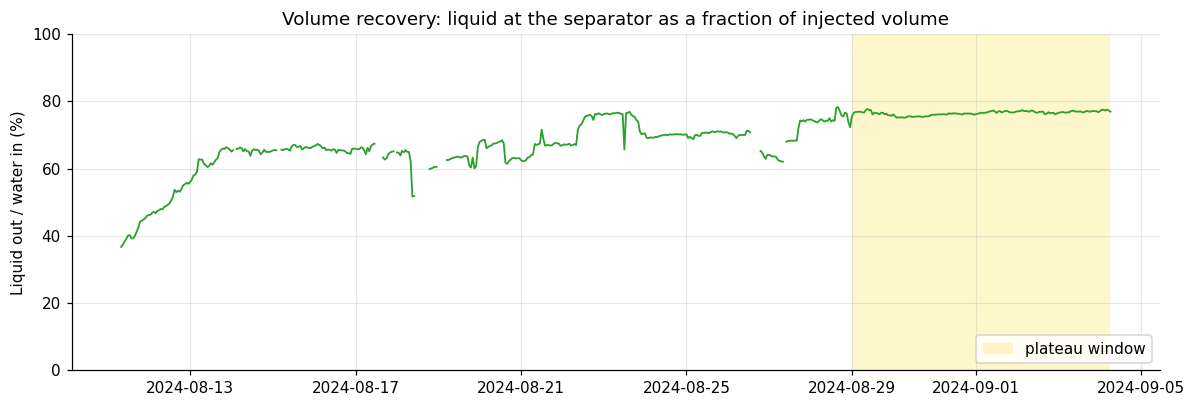

Whole steady period : 69%   (notebook 02 said 70%: that was the ratio of the two medians; this is the median of the ratio. Same idea, tiny rounding difference.)
Plateau window      : 77%


In [5]:
hs["vol_recovery"] = hs["sep_total_corr_gpm"] / hs["inj_gpm"]

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(hs.index, hs["vol_recovery"] * 100, color="tab:green", lw=1.2)
shade_window(ax, plateau.index.min(), plateau.index.max(), label="plateau window")
ax.set_ylabel("Liquid out / water in (%)"); ax.set_ylim(0, 100)
ax.set_title("Volume recovery: liquid at the separator as a fraction of injected volume")
ax.legend(loc="lower right")
savefig(fig, "03_volume_recovery.png"); plt.show()

print(f"Whole steady period : {(steady['sep_total_corr_gpm'] / steady['inj_gpm']).median()*100:.0f}%   (notebook 02 said 70%: that was the ratio of the two medians; this is the median of the ratio. Same idea, tiny rounding difference.)")
print(f"Plateau window      : {(plateau['sep_total_corr_gpm'] / plateau['inj_gpm']).median()*100:.0f}%")

Recovery climbs from about 40% on the first day to roughly **77%** on the plateau. Two reasons it is below 100%:
1. **Steam:** about a fifth of the hot water becomes steam at the separator, which the liquid meters do not see.
2. **Water still in the rock** or lost into the formation.

To separate these two we need to count the steam. In notebook 02 we used the report's 19.6%. Now we calculate it ourselves.

## 4. Steam: calculating the flash fraction

Water at 375 °F under pressure in the well is a liquid. When it reaches the separator it drops to atmospheric pressure, and since the pressure is lower, the water can only stay liquid below its boiling point, about 202 °F here (the site is at 5,415 ft elevation, so the air pressure is lower than at sea level). The extra heat has to go somewhere, and it **boils off part of the water as steam**.

An energy balance tells us how much:

$$\text{steam fraction} = \frac{h_\text{liquid}(T_\text{well}) - h_\text{liquid}(T_\text{boil})}{h_\text{fg}}$$

where *h* is the energy content of water (enthalpy, in kJ/kg) and $h_\text{fg}$ is the energy needed to boil one kg. We get *h* from standard **steam tables**, using the `iapws` library.

First, the separator conditions:

In [6]:
sep = separator_conditions()          # uses elevation 5,415 ft
print(f"Air pressure at the separator : {sep['p_MPa']*1000:.1f} kPa")
print(f"Boiling point (calculated)    : {sep['T_boil_F']:.1f} °F   (report: 202.2 °F)")
print(f"Density of liquid at boiling  : {sep['rho_liquid']:.0f} kg/m³")
print(f"Energy to boil 1 kg           : {sep['h_fg']:.0f} kJ/kg")

Air pressure at the separator : 83.0 kPa
Boiling point (calculated)    : 202.1 °F   (report: 202.2 °F)
Density of liquid at boiling  : 962 kg/m³
Energy to boil 1 kg           : 2271 kJ/kg


The boiling point we calculate from altitude agrees with the report to within 0.1 °F, so the setup is right. Now the steam fraction for a range of well temperatures:

In [7]:
temps = np.array([300, 340, 360, 375, 380, 390])
pd.DataFrame({"well temperature (°F)": temps,
              "steam fraction (%)": (steam_fraction(temps, sep) * 100).round(1)}).set_index("well temperature (°F)")

,steam fraction (%)
well temperature (°F),
300,10.2
340,14.5
360,16.6
375,18.2
380,18.8
390,19.9


> **Learn:** looking up steam tables 80,000 times would be slow, so `analysis.py` calculates the table once on a 1 °F grid and then uses `np.interp(x, grid_x, grid_y)` to read off values between grid points. It's a standard speed-up whenever you evaluate an expensive function many times.

Now our calculated steam fraction through the test, compared with the report's 19.6%:

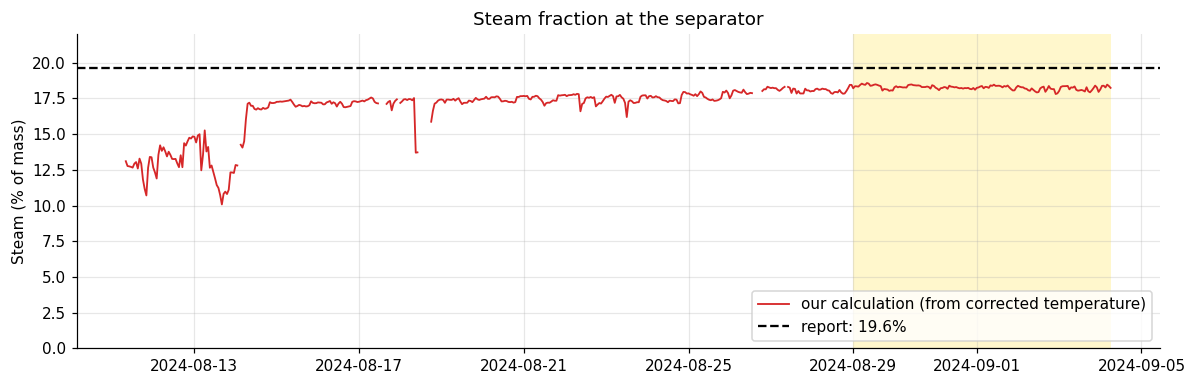

Plateau: temperature 375 °F  ->  steam 18.3%
The report's 19.6% corresponds to a well temperature of about 387 °F in this energy balance.


In [8]:
hs["steam_frac"] = mf["steam_frac"].resample("1h").median()
T_for_report = np.interp(0.196, steam_fraction(np.arange(300, 400.0), sep), np.arange(300, 400.0))

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(hs.index, hs["steam_frac"] * 100, color="tab:red", lw=1.2, label="our calculation (from corrected temperature)")
ax.axhline(19.6, color="k", ls="--", label="report: 19.6%")
shade_window(ax, plateau.index.min(), plateau.index.max())
ax.set_ylabel("Steam (% of mass)"); ax.set_ylim(0, 22)
ax.set_title("Steam fraction at the separator"); ax.legend(loc="lower right")
savefig(fig, "03_steam_fraction.png"); plt.show()

print(f"Plateau: temperature {plateau['T16B_corr_F'].median():.0f} °F  ->  steam {mf.loc[plateau.index, 'steam_frac'].median()*100:.1f}%")
print(f"The report's 19.6% corresponds to a well temperature of about {T_for_report:.0f} °F in this energy balance.")

Our steam fraction rises with the temperature and settles at about **18%**, a bit below the report's **19.6%**. The report's number would need a well temperature around 387 °F, about 12 °F hotter than ours. That gap is similar to the size of our temperature correction (+11 °F, with ±4.6 °F spread), so the two are consistent given the uncertainty. We'll test how much it matters in section 6.

## 5. Mass flow and efficiency

Volumes are misleading here, because hot water, cold water and steam have different densities. The report therefore compares **mass flow rates** (kg/s):

- **Injected mass** = injected volume × density of the cold water. The injection water temperature is **not in our dataset**; the report says it was *ambient-temperature pit water*, so we assume **20 °C (68 °F)** and test that assumption later.
- **Produced mass** = liquid at the separator (volume × density at the boiling point) **plus** the steam. If steam is a fraction *x* of the total, then total = liquid ÷ (1 − *x*).
- **Efficiency** = produced mass ÷ injected mass.

`mass_flows()` in `src/analysis.py` does exactly this. We already ran it in section 1. Let's look at the results.

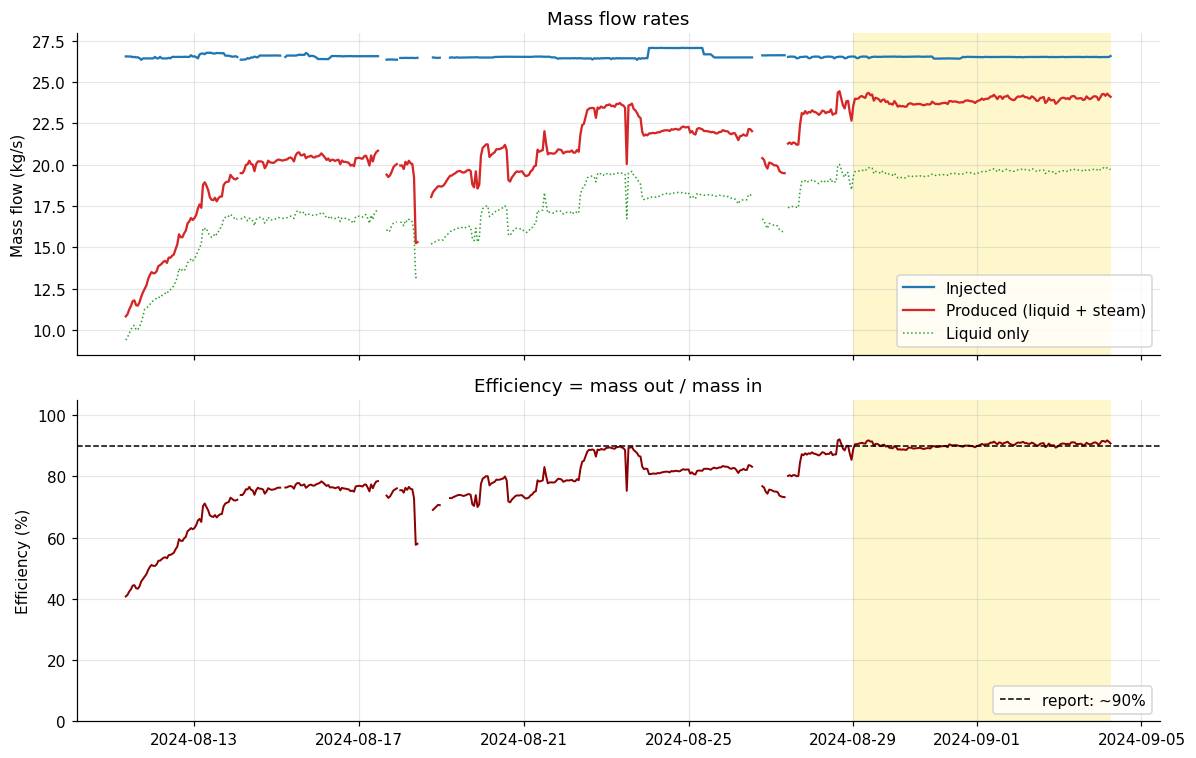

In [9]:
hm = mf.resample("1h").median()

fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
ax[0].plot(hm.index, hm["inj_kg_s"], color="tab:blue", label="Injected")
ax[0].plot(hm.index, hm["produced_kg_s"], color="tab:red", label="Produced (liquid + steam)")
ax[0].plot(hm.index, hm["sep_liquid_kg_s"], color="tab:green", lw=1, ls=":", label="Liquid only")
ax[0].set_ylabel("Mass flow (kg/s)"); ax[0].set_title("Mass flow rates"); ax[0].legend(loc="lower right")

ax[1].plot(hm.index, hm["efficiency"] * 100, color="darkred", lw=1.3)
ax[1].axhline(90, color="k", ls="--", lw=1, label="report: ~90%")
for a in ax:
    shade_window(a, plateau.index.min(), plateau.index.max())
ax[1].set_ylabel("Efficiency (%)"); ax[1].set_ylim(0, 105); ax[1].legend(loc="lower right")
ax[1].set_title("Efficiency = mass out / mass in")
savefig(fig, "03_mass_flow_efficiency.png"); plt.show()

In [10]:
p = mf.loc[plateau.index]
print("PLATEAU WINDOW (medians)")
print(f"  Injected mass flow : {p['inj_kg_s'].median():5.1f} kg/s   (report: ~26.5 kg/s)")
print(f"  Produced mass flow : {p['produced_kg_s'].median():5.1f} kg/s   (report figure: ~23 kg/s at the end)")
print(f"  Efficiency         : {p['efficiency'].median()*100:5.1f} %      middle 50% of readings: {p['efficiency'].quantile(.25)*100:.1f} to {p['efficiency'].quantile(.75)*100:.1f} %   (report: ~90%)")

PLATEAU WINDOW (medians)
  Injected mass flow :  26.5 kg/s   (report: ~26.5 kg/s)
  Produced mass flow :  23.9 kg/s   (report figure: ~23 kg/s at the end)
  Efficiency         :  90.3 %      middle 50% of readings: 89.7 to 90.8 %   (report: ~90%)


**We reproduce the report's headline result independently: about 90% efficiency**, with an injected flow of 26.5 kg/s that matches the report exactly. The produced flow is about 24 kg/s, in the range of the report's figure.

**Why this is a good sign:** we did not tune anything to hit 90%. The result comes from the calibration, the temperature correction and steam-table physics, all based on the raw data.

> **A correction to notebook 02.** There I did a rough check and got "87% with steam". That was a shortcut which divided volumes and ignored that the produced liquid is much hotter (lighter) than the injected water. The proper mass calculation above gives about 90%. The shortcut happened to land close, but this is the right way to do it.

The daily picture shows how the well evolved:

In [11]:
daily = pd.DataFrame({
    "injection (gpm)": steady["inj_gpm"].groupby(steady.index.date).median(),
    "inj. pressure (psi)": steady["p_inj_psi"].groupby(steady.index.date).median(),
    "liquid out (gpm)": steady["sep_total_corr_gpm"].groupby(steady.index.date).median(),
    "temperature (°F)": steady["T16B_corr_F"].groupby(steady.index.date).median(),
    "steam (%)": mf["steam_frac"].groupby(steady.index.date).median() * 100,
    "produced (kg/s)": mf["produced_kg_s"].groupby(steady.index.date).median(),
    "efficiency (%)": mf["efficiency"].groupby(steady.index.date).median() * 100,
})
daily["injectivity (gpm/100psi)"] = daily["injection (gpm)"] / daily["inj. pressure (psi)"] * 100
daily.index.name = "date"
daily.round(1)

,injection (gpm),inj. pressure (psi),liquid out (gpm),temperature (°F),steam (%),produced (kg/s),efficiency (%),injectivity (gpm/100psi)
date,,,,,,,,
2024-08-11,420.7,2752.1,169.7,324.7,12.8,11.8,44.6,15.3
2024-08-12,420.9,2815.2,207.4,331.9,13.6,14.5,54.8,15.0
2024-08-13,423.6,2865.9,263.7,320.7,12.4,18.1,67.8,14.8
2024-08-14,420.8,2852.1,275.1,362.1,16.8,20.0,75.5,14.8
2024-08-15,422.5,2899.0,278.7,365.3,17.2,20.4,76.9,14.6
2024-08-16,420.3,2914.0,276.6,365.1,17.2,20.3,76.4,14.4
2024-08-17,420.3,2952.1,277.0,366.5,17.3,20.3,76.6,14.2
2024-08-18,420.2,2916.5,267.1,366.8,17.3,19.6,74.9,14.4
2024-08-19,420.4,2930.3,264.5,367.1,17.4,19.4,73.6,14.3


Read the last columns top to bottom: the efficiency starts near 45% (the fracture network is still filling with water) and climbs to about 90%. The temperature rises from about 320 to 375 °F over the same time.

It is **not a smooth climb**, though. The efficiency reached about 89% on 23 Aug, then fell back to about 82% after the injection-rate bump on 24 Aug and the half-rate period on 26 Aug, and only recovered to 90% by 29 Aug. Flow changes disturb the system, and it needs days to settle again, which is exactly why we measure on a plateau rather than averaging the whole test. The report hypothesised exactly this for the earlier 9-hour test: *"this efficiency will increase with time as the created fracture system is filled and stiffened and connections improve."*

## 6. How sure are we? (sensitivity analysis)

"About 90%" sounds precise, but we made choices along the way. Good analysis tests how much each choice matters: change one thing at a time, recompute the efficiency, and see how far it moves.

| What we vary | Why it is uncertain |
|---|---|
| Injection water temperature (10 to 30 °C) | Not in our dataset; we assumed 20 °C |
| Calibration line: through the origin instead of with an intercept | The report shows its equations only in a figure |
| Temperature offset ±4.6 °F (one standard deviation) | The manual readings scatter by this much |
| Raw temperature, no correction at all | What if the correction were wrong? |
| Steam fixed at the report's 19.6% of the total | The report's number instead of ours |
| Steam of 19.6% *added to* the liquid mass | A different way to read the report's wording |

In [12]:
cal = load_flow_calibration()
const = load_constants()
manual = load_manual_tp()
_, T_spread, _ = temperature_offset(manual)

def eff(frame, **kw):
    return mass_flows(frame, **kw)["efficiency"].median()

# --- Alternative calibration: best straight line forced through (0, 0) ---
alt = plateau.copy()
for m, cal_col in [("sep1", "sep1_raw_gpm"), ("sep2", "sep2_raw_gpm")]:
    a, b = const.loc[f"{m}_gpm", "slope"], const.loc[f"{m}_gpm", "intercept"]
    raw = (plateau[f"{m}_corr_gpm"] - b) / a                 # undo our correction -> raw meter reading
    x, y = cal[cal_col].values, cal["liberty_gpm"].values
    slope0 = (x * y).sum() / (x * x).sum()                   # least-squares slope with no intercept
    alt[f"{m}_o"] = raw * slope0
alt["sep_total_corr_gpm"] = alt["sep1_o"] + alt["sep2_o"]

def shifted(dT):
    f = plateau.copy(); f["T16B_corr_F"] = f["T16B_corr_F"] + dT; return f

base = eff(plateau)
scenarios = {
    "Injection water 10 °C":                     eff(plateau, T_inj_C=10),
    "Injection water 30 °C":                     eff(plateau, T_inj_C=30),
    "Calibration through the origin":            eff(alt),
    f"Temperature offset -{T_spread:.1f} °F":    eff(shifted(-T_spread)),
    f"Temperature offset +{T_spread:.1f} °F":    eff(shifted(+T_spread)),
    "Raw temperature (no correction)":           eff(plateau, T_col="T16B_F"),
    "Steam fixed at 19.6% of total (report)":    eff(plateau, steam_x=0.196),
    "Steam 19.6% added to the liquid":           eff(plateau, steam_x=0.196 / 1.196),
}
sens = pd.Series(scenarios, name="efficiency")
table = pd.DataFrame({"efficiency (%)": sens * 100, "change vs base (points)": (sens - base) * 100})
print(f"BASE CASE: {base*100:.1f}%\n")
table.round(1)

BASE CASE: 90.3%



,efficiency (%),change vs base (points)
Injection water 10 °C,90.1,-0.1
Injection water 30 °C,90.5,0.2
Calibration through the origin,92.2,1.9
Temperature offset -4.6 °F,89.7,-0.5
Temperature offset +4.6 °F,90.8,0.6
Raw temperature (no correction),88.9,-1.3
Steam fixed at 19.6% of total (report),91.8,1.5
Steam 19.6% added to the liquid,88.3,-2.0


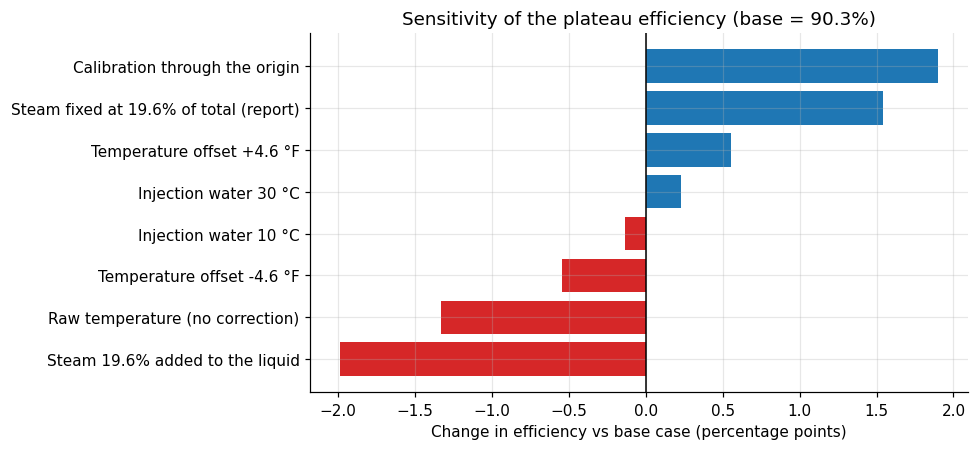

Across all scenarios the plateau efficiency ranges from 88.3% to 92.2%.


Without counting any steam at all it would be only 74%, so steam matters far more than any single choice here.


In [13]:
change = (sens - base) * 100
order = change.sort_values()

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.barh(order.index, order.values, color=["tab:red" if v < 0 else "tab:blue" for v in order.values])
ax.axvline(0, color="k", lw=1)
ax.set_xlabel("Change in efficiency vs base case (percentage points)")
ax.set_title(f"Sensitivity of the plateau efficiency (base = {base*100:.1f}%)")
savefig(fig, "03_sensitivity.png"); plt.show()

lo, hi = sens.min() * 100, sens.max() * 100
print(f"Across all scenarios the plateau efficiency ranges from {lo:.1f}% to {hi:.1f}%.")
print(f"Without counting any steam at all it would be only {eff(plateau, steam_x=0.0)*100:.0f}%, so steam matters far more than any single choice here.")

> **Learn:** `ax.barh(labels, values)` draws horizontal bars. Sorted bars like this are often called a *tornado chart*: the biggest uncertainties end up at the top and bottom, so you can see at a glance what matters most.

**Reading this:**
- The result is **robust**: every reasonable choice lands between about 88% and 92%.
- The two most influential choices are **how the calibration line is drawn** (+1.9 points) and **how the steam fraction is defined** (about −2 to +1.5 points). Everything else moves it by less than 1.5 points.
- The injection water temperature barely matters (±0.2 points), so our assumption of 20 °C is safe.

So the honest statement is **"about 90%, plausibly 88–92%"**.

## 7. Key results and saving

In [14]:
key = pd.Series({
    "plateau length (days)": plateau.index.normalize().nunique(),
    "injection rate (gpm)": plateau["inj_gpm"].median(),
    "injection rate (kg/s)": p["inj_kg_s"].median(),
    "injection pressure (psi)": plateau["p_inj_psi"].median(),
    "pressure trend after peak (psi/day)": p_trend["slope_per_day"],
    "injectivity (gpm/100psi)": injectivity_index(plateau).median(),
    "producer temperature, corrected (F)": plateau["T16B_corr_F"].median(),
    "steam fraction (%)": p["steam_frac"].median() * 100,
    "volume recovery, liquid only (%)": (plateau["sep_total_corr_gpm"] / plateau["inj_gpm"]).median() * 100,
    "produced mass flow (kg/s)": p["produced_kg_s"].median(),
    "efficiency, base case (%)": base * 100,
    "efficiency, lowest scenario (%)": lo,
    "efficiency, highest scenario (%)": hi,
}, name="value")

key.round(2).to_csv("../data/processed/key_results.csv", index_label="metric")
daily.round(3).to_csv("../data/processed/performance_daily.csv")
print(f"Plateau window: {plateau_start} to {plateau.index.max().date()}")
key.round(2).to_frame()

Plateau window: 2024-08-29 to 2024-09-04


,value
plateau length (days),7.00
injection rate (gpm),420.88
injection rate (kg/s),26.51
injection pressure (psi),2825.25
pressure trend after peak (psi/day),-11.07
injectivity (gpm/100psi),14.91
"producer temperature, corrected (F)",375.32
steam fraction (%),18.27
"volume recovery, liquid only (%)",76.58
produced mass flow (kg/s),23.93


## Summary

| Question | Answer |
|---|---|
| Injection pressure | ~2,825 psi on the plateau, falling ~11 psi/day (about 5% over 2 weeks) after the late-August peak |
| Injectivity | ~14.9 gpm per 100 psi, rising as the pressure falls |
| Volume recovery (liquid only) | ~77% on the plateau, up from ~40% on day one |
| Steam fraction | ~18%, calculated from steam tables (report: 19.6%) |
| **Mass efficiency** | **~90% (plausible range 88–92%)**, matching the report's ~90% |
| Biggest uncertainties | calibration form and the definition of steam fraction |

### Caveats to state in the README
- Injection water temperature is assumed (20 °C); it barely matters.
- Injectivity is based on *wellhead* pressure, so only its trend is meaningful.
- The steady-state window is chosen by a rule (within 2% of the final efficiency), and the efficiency was still creeping up slightly inside it.

### Next: `04_power_decline`
Heat output is the product of **mass flow × (energy of the produced fluid − energy of the injected fluid)**. The notebook is called *power decline*, but here the temperature and flow are both **rising**, so the data may show power *increasing*. We will let the data decide, and name the notebook honestly in the README.